# Growth, Inflation and Living Standards in Five African Economies, 2000–2025

> ⚠️ **For class teaching purposes only.** This notebook was prepared to teach data analysis with Python and open economic data. It is **not** a research paper, policy analysis or official statistical report. The country selection and time period are teaching choices (see **Scope and selection** below), the results are descriptive, and World Bank figures are revised over time. **Readers should be cautious about using these results in reports, publications or decisions.** Always check figures against the latest official sources and apply your own methods.

An economic analysis of **Ghana, Nigeria, Côte d'Ivoire, Kenya and South Africa**, compared with the **Sub-Saharan Africa** average, using open data from the World Bank.

**Questions**

1. Whose living standards (real GDP per person) rose the most since 2000?
2. Which economies grew fastest, and which most steadily?
3. How have inflation episodes differed across countries?
4. Do years of high inflation tend to be years of slower growth?
5. **Ghana deep dive:** how closely does inflation follow the cedi's depreciation?

**Data:** [World Bank World Development Indicators](https://data.worldbank.org/), downloaded through the public API (no key needed) and cached in `data/raw/` so the results are reproducible.

## Scope and selection

This analysis covers five countries over 2000–2025. These are **teaching choices made to show clear contrasts**, not a representative sample of Sub-Saharan Africa.

**Why these countries**

| Country | Role in the comparison |
|---|---|
| **Ghana** | Focus country and the subject of the deep dive on currency and inflation |
| **Nigeria** | Large West African neighbour, oil exporter, floating currency |
| **Côte d'Ivoire** | West African neighbour using the CFA franc, which is pegged to the euro. It provides a contrast with Ghana's floating cedi |
| **Kenya** | East African comparison with a diversified, non-oil economy |
| **South Africa** | The region's most industrialised and highest-income economy in this group |
| **Sub-Saharan Africa** | Regional average, used as a benchmark |

Five countries also keep the charts readable for teaching.

**Why 2000–2025**

- **2025** is the latest complete year available from the World Bank at the time of download (November 2026).
- **2000** gives a 25-year window that includes the 2000s commodity boom, the 2008–09 global financial crisis, the 2014–16 oil-price fall, COVID-19 in 2020, and Ghana's 2022–23 debt and inflation crisis.

**What this means for the results**

- Findings describe **these five economies only** and should not be generalised to the whole region.
- Ghana was chosen as the focus country **before** the analysis. Its strong performance is a result, not a reason for selecting it.
- **Results depend on the start year.** Indexed growth (2000 = 100) and inflation peaks would differ with another start year. For example, Côte d'Ivoire looks weaker partly because 2000 came just before its crisis years, and Ghana's inflation was unusually high in 2000–01.
- To test this, change `COUNTRIES` or `START` in the setup cell below, set `REFRESH = True`, and re-run.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.worldbank import load_indicators

pd.set_option("display.precision", 1)

COUNTRIES = {"GHA": "Ghana", "NGA": "Nigeria", "CIV": "Côte d'Ivoire", "KEN": "Kenya", "ZAF": "South Africa"}
BENCHMARK = {"SSF": "Sub-Saharan Africa"}
INDICATORS = {
    "NY.GDP.MKTP.KD.ZG": "gdp_growth",       # GDP growth, annual %
    "FP.CPI.TOTL.ZG": "inflation",           # consumer-price inflation, annual %
    "NY.GDP.PCAP.KD": "gdp_per_capita",      # GDP per person, constant 2015 US$
    "SL.UEM.TOTL.ZS": "unemployment",        # unemployment, % of labour force (ILO modelled estimate)
    "PA.NUS.FCRF": "exchange_rate",          # local currency units per US$, period average
}
START, END = 2000, 2025
REFRESH = False   # set to True to download the latest figures from the World Bank

In [2]:
# Chart style: one fixed colour per country, used in every chart
COLORS = {"GHA": "#2a78d6", "NGA": "#eb6834", "CIV": "#1baf7a", "KEN": "#eda100", "ZAF": "#e87ba4", "SSF": "#8a8984"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e9e8e4"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "axes.axisbelow": True, "lines.linewidth": 2, "legend.frameon": False,
})

def source_note(fig, text="Source: World Bank, World Development Indicators."):
    fig.text(0.01, -0.02, text, fontsize=8, color=MUTED, ha="left")

## 2. Load the data

In [3]:
raw = load_indicators(INDICATORS, list(COUNTRIES) + list(BENCHMARK), START, END,
                      cache=ROOT / "data" / "raw" / "worldbank_indicators.csv", refresh=REFRESH)

df = (raw.pivot_table(index=["country_code", "year"], columns="series", values="value")
         .reset_index()
         .assign(country=lambda d: d["country_code"].map({**COUNTRIES, **BENCHMARK})))
print(f"{len(raw):,} observations · {df['country_code'].nunique()} economies · {df['year'].min()}–{df['year'].max()}")
df.tail()

780 observations · 6 economies · 2000–2025


series,country_code,year,exchange_rate,gdp_growth,gdp_per_capita,inflation,unemployment,country
151,ZAF,2021,14.8,4.9,5750.9,4.6,34.0,South Africa
152,ZAF,2022,16.4,2.1,5786.9,7.0,33.3,South Africa
153,ZAF,2023,18.5,0.8,5756.6,6.1,32.1,South Africa
154,ZAF,2024,18.3,0.5,5715.5,4.4,32.3,South Africa
155,ZAF,2025,17.9,1.1,5713.1,3.2,32.4,South Africa


## 3. Check the data first

Before analysing anything, confirm how complete each series is. A gap here would change how the results should be read.

*Note: the World Bank does not publish an exchange rate for the regional aggregate, so that cell is expected to be empty.*

In [4]:
coverage = (raw.assign(has_value=raw["value"].notna())
               .pivot_table(index="series", columns="country_code", values="has_value", aggfunc="mean")
               [list(COUNTRIES) + list(BENCHMARK)]
               .rename_axis(index=None, columns=None))
coverage.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=1)

,GHA,NGA,CIV,KEN,ZAF,SSF
exchange_rate,100%,100%,100%,100%,100%,0%
gdp_growth,100%,100%,100%,100%,100%,100%
gdp_per_capita,100%,100%,100%,100%,100%,100%
inflation,100%,100%,100%,100%,100%,100%
unemployment,100%,100%,100%,100%,100%,100%


## 4. Living standards: real GDP per person

Indexed to **2000 = 100**, so the lines show growth since 2000 rather than levels.

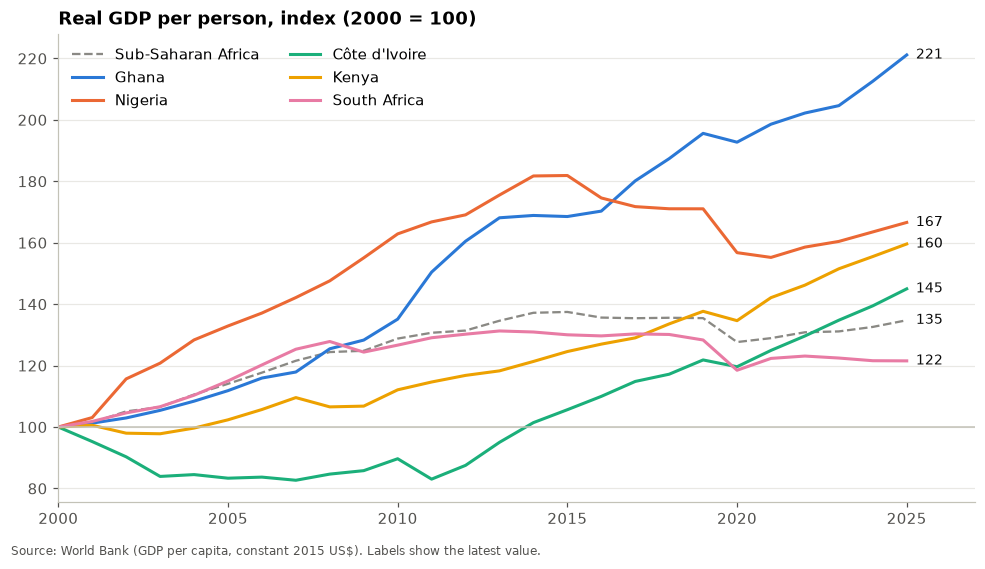

In [5]:
pc = df.pivot(index="year", columns="country_code", values="gdp_per_capita")
index = pc / pc.loc[START] * 100

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(index.index, index["SSF"], color=COLORS["SSF"], linestyle="--", linewidth=1.5, label="Sub-Saharan Africa")
for code, name in COUNTRIES.items():
    ax.plot(index.index, index[code], color=COLORS[code], label=name)
for code in list(COUNTRIES) + ["SSF"]:
    ax.annotate(f"{index[code].iloc[-1]:.0f}", (index.index[-1], index[code].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
ax.axhline(100, color="#c3c2b7", linewidth=1)
ax.set_title("Real GDP per person, index (2000 = 100)")
ax.set_xlim(START, END + 2)
ax.legend(loc="upper left", ncol=2)
source_note(fig, "Source: World Bank (GDP per capita, constant 2015 US$). Labels show the latest value.")
plt.tight_layout()
plt.show()

In [6]:
levels = pd.DataFrame({
    f"{START} (US$)": pc.loc[START], f"{END} (US$)": pc.loc[END],
    "change (%)": (pc.loc[END] / pc.loc[START] - 1) * 100,
    "avg. annual (%)": ((pc.loc[END] / pc.loc[START]) ** (1 / (END - START)) - 1) * 100,
}).rename(index={**COUNTRIES, **BENCHMARK}).rename_axis(None).sort_values("change (%)", ascending=False)
levels.style.format({f"{START} (US$)": "{:,.0f}", f"{END} (US$)": "{:,.0f}", "change (%)": "{:+.0f}", "avg. annual (%)": "{:.1f}"})

,2000 (US$),2025 (US$),change (%),avg. annual (%)
Ghana,"1,022","2,261",+121,3.2
Nigeria,"1,422","2,369",+67,2.1
Kenya,"1,195","1,908",+60,1.9
Côte d'Ivoire,"1,718","2,491",+45,1.5
Sub-Saharan Africa,"1,198","1,615",+35,1.2
South Africa,"4,701","5,713",+22,0.8


## 5. Growth: how fast, and how steady?

Average annual GDP growth, with its **standard deviation** as a simple measure of volatility. The **coefficient of variation** (volatility ÷ average) shows how much instability comes with each point of growth.

In [7]:
growth = df.pivot(index="year", columns="country_code", values="gdp_growth")
stats = pd.DataFrame({
    "avg. growth (%)": growth.mean(),
    "volatility (st. dev.)": growth.std(),
    "worst year (%)": growth.min(),
    "worst year": growth.idxmin(),
})
stats["coef. of variation"] = stats["volatility (st. dev.)"] / stats["avg. growth (%)"]
stats = stats.rename(index={**COUNTRIES, **BENCHMARK}).rename_axis(None).sort_values("avg. growth (%)", ascending=False)
stats.style.format({"avg. growth (%)": "{:.1f}", "volatility (st. dev.)": "{:.1f}", "worst year (%)": "{:.1f}", "coef. of variation": "{:.2f}"})

,avg. growth (%),volatility (st. dev.),worst year (%),worst year,coef. of variation
Ghana,5.6,2.7,0.5,2020,0.48
Nigeria,4.8,4.0,-6.4,2020,0.84
Kenya,4.4,2.1,-0.3,2020,0.49
Côte d'Ivoire,3.9,4.3,-5.4,2011,1.09
Sub-Saharan Africa,3.9,2.0,-3.3,2020,0.52
South Africa,2.2,2.5,-6.2,2020,1.13


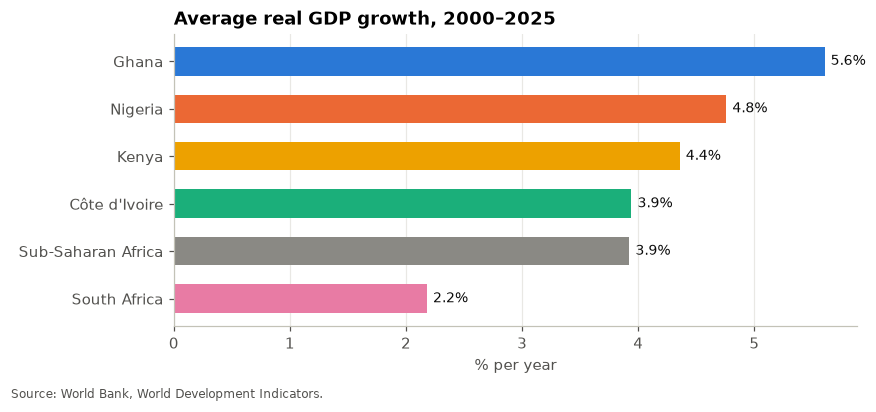

In [8]:
order = stats.index[::-1]
code_of = {v: k for k, v in {**COUNTRIES, **BENCHMARK}.items()}

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(order, stats.loc[order, "avg. growth (%)"], color=[COLORS[code_of[n]] for n in order], height=0.6)
ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9, color=INK)
ax.set_title(f"Average real GDP growth, {START}–{END}")
ax.set_xlabel("% per year")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
source_note(fig)
plt.tight_layout()
plt.show()

## 6. Inflation episodes

One panel per country on the **same scale**, with the regional average as a grey reference line.

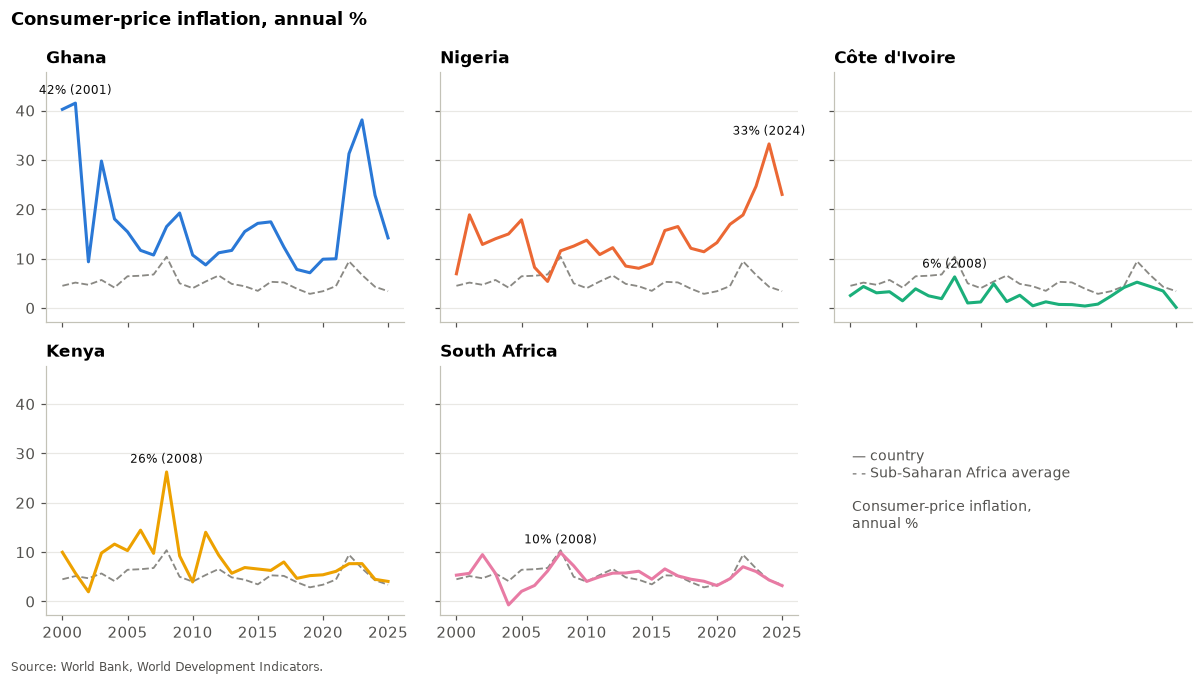

In [9]:
infl = df.pivot(index="year", columns="country_code", values="inflation")

fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True, sharey=True)
for ax, (code, name) in zip(axes.flat, COUNTRIES.items()):
    ax.plot(infl.index, infl["SSF"], color=COLORS["SSF"], linestyle="--", linewidth=1.2)
    ax.plot(infl.index, infl[code], color=COLORS[code])
    peak_year = infl[code].idxmax()
    ax.annotate(f"{infl[code].max():.0f}% ({peak_year})", (peak_year, infl[code].max()),
                xytext=(0, 6), textcoords="offset points", ha="center", fontsize=8, color=INK)
    ax.set_title(name, fontsize=11)
axes.flat[0].set_ylim(top=infl[list(COUNTRIES)].max().max() * 1.15)
axes.flat[-1].axis("off")
axes.flat[-1].text(0.05, 0.5, "— country\n- - Sub-Saharan Africa average\n\nConsumer-price inflation,\nannual %",
                   color=MUTED, fontsize=9, va="center", transform=axes.flat[-1].transAxes)
fig.suptitle("Consumer-price inflation, annual %", x=0.01, ha="left", fontweight="bold")
source_note(fig)
plt.tight_layout()
plt.show()

In [10]:
inflation_summary = pd.DataFrame({
    "median (%)": infl.median(),
    "years above 10%": (infl > 10).sum(),
    "peak (%)": infl.max(),
    "peak year": infl.idxmax(),
    f"{END} (%)": infl.loc[END],
}).rename(index={**COUNTRIES, **BENCHMARK}).rename_axis(None).sort_values("median (%)", ascending=False)
inflation_summary.style.format({"median (%)": "{:.1f}", "peak (%)": "{:.1f}", f"{END} (%)": "{:.1f}"})

,median (%),years above 10%,peak (%),peak year,2025 (%)
Ghana,14.8,20,41.5,2001,14.2
Nigeria,13.1,20,33.2,2024,23.0
Kenya,7.3,5,26.2,2008,4.1
South Africa,5.3,0,9.9,2008,3.2
Sub-Saharan Africa,4.9,1,10.4,2008,3.4
Côte d'Ivoire,2.4,0,6.3,2008,0.1


## 7. Does high inflation come with slower growth?

Each dot is one year. The number in each title is the **correlation** between inflation and growth in the same year (−1 to +1).

> Correlation is not causation. With about 26 points per country, these are descriptive patterns, not estimates of cause and effect.

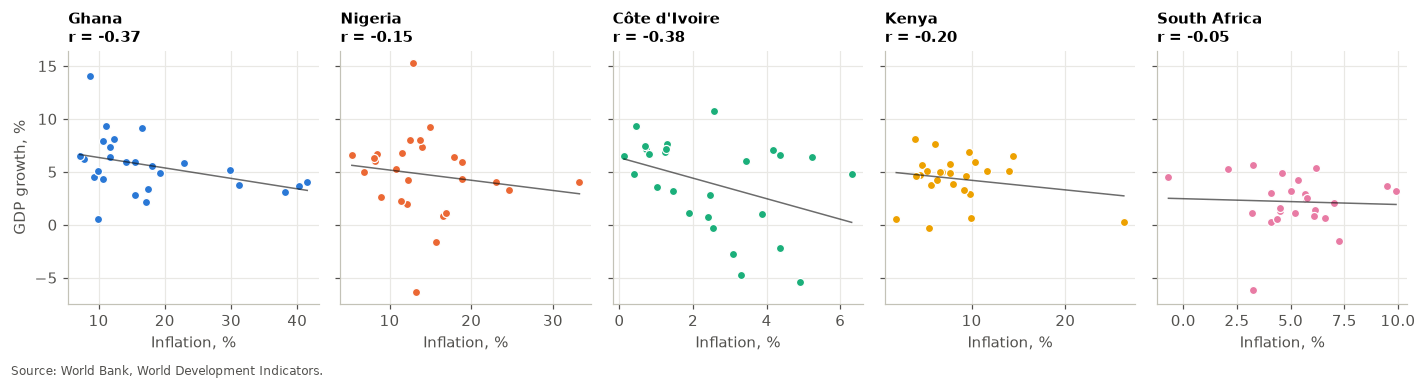

,correlation (inflation vs growth)
Ghana,-0.37
Nigeria,-0.15
Côte d'Ivoire,-0.38
Kenya,-0.20
South Africa,-0.05


In [11]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3.4), sharey=True)
corr = {}
for ax, (code, name) in zip(axes, COUNTRIES.items()):
    d = df[df["country_code"] == code].dropna(subset=["inflation", "gdp_growth"])
    r = d["inflation"].corr(d["gdp_growth"])
    corr[name] = r
    ax.scatter(d["inflation"], d["gdp_growth"], s=28, color=COLORS[code], edgecolor="white", linewidth=0.8)
    slope, intercept = np.polyfit(d["inflation"], d["gdp_growth"], 1)
    xs = np.linspace(d["inflation"].min(), d["inflation"].max(), 50)
    ax.plot(xs, intercept + slope * xs, color=INK, linewidth=1, alpha=0.6)
    ax.set_title(f"{name}\nr = {r:+.2f}", fontsize=10)
    ax.set_xlabel("Inflation, %")
    ax.grid(axis="x", visible=True)
axes[0].set_ylabel("GDP growth, %")
source_note(fig)
plt.tight_layout()
plt.show()

pd.Series(corr, name="correlation (inflation vs growth)").to_frame().style.format("{:+.2f}")

## 8. Ghana deep dive: the cedi and inflation

Annual **depreciation** is the % rise in cedis needed to buy one US dollar. The two measures are on different scales, so they get **separate panels** with a shared time axis rather than one chart with two y-axes.

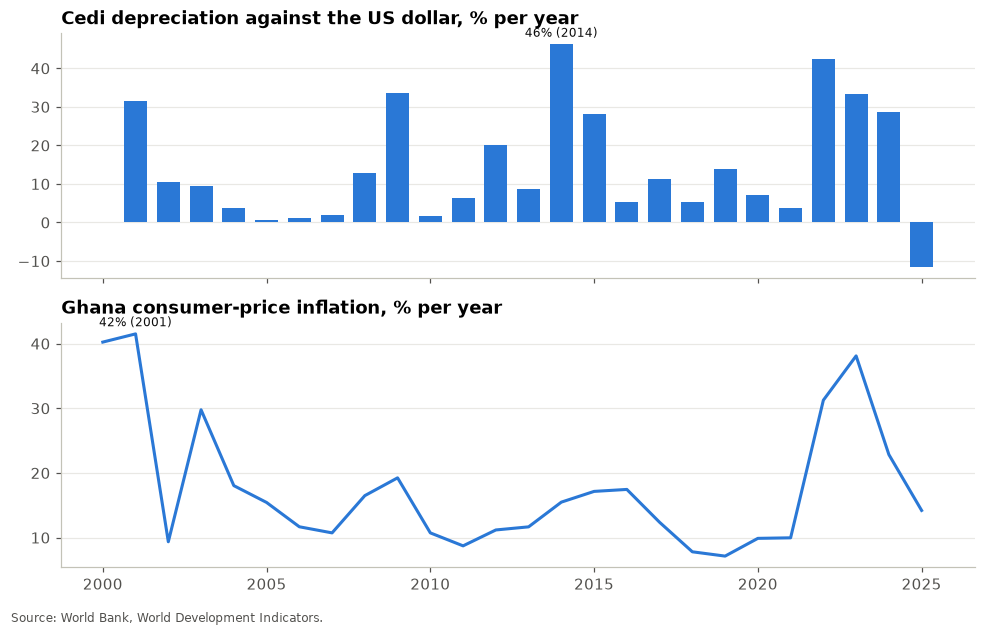

In [12]:
gh = df[df["country_code"] == "GHA"].set_index("year").sort_index()
gh["depreciation"] = gh["exchange_rate"].pct_change() * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True)
ax1.bar(gh.index, gh["depreciation"], color=COLORS["GHA"], width=0.7)
ax1.set_title("Cedi depreciation against the US dollar, % per year")
ax2.plot(gh.index, gh["inflation"], color=COLORS["GHA"])
ax2.set_title("Ghana consumer-price inflation, % per year")
for ax, col in ((ax1, "depreciation"), (ax2, "inflation")):
    yr = gh[col].idxmax()
    ax.annotate(f"{gh[col].max():.0f}% ({yr})", (yr, gh[col].max()), xytext=(0, 5),
                textcoords="offset points", ha="center", fontsize=8, color=INK)
source_note(fig)
plt.tight_layout()
plt.show()

In [13]:
pair = gh[["depreciation", "inflation"]].dropna()
same_year = pair["depreciation"].corr(pair["inflation"])
next_year = gh["depreciation"].corr(gh["inflation"].shift(-1))
print(f"Correlation, depreciation vs inflation in the same year: {same_year:+.2f}")
print(f"Correlation, depreciation vs inflation the following year: {next_year:+.2f}")

Correlation, depreciation vs inflation in the same year: +0.57
Correlation, depreciation vs inflation the following year: +0.30


## 9. Latest snapshot

In [14]:
snapshot = (df[df["year"] == END]
            .set_index("country").rename_axis(None)[["gdp_growth", "inflation", "unemployment", "gdp_per_capita"]]
            .rename(columns={"gdp_growth": "GDP growth (%)", "inflation": "inflation (%)",
                             "unemployment": "unemployment (%)", "gdp_per_capita": "GDP per person (2015 US$)"})
            .sort_values("GDP per person (2015 US$)", ascending=False))
print(f"Year: {END}")
snapshot.style.format({"GDP growth (%)": "{:.1f}", "inflation (%)": "{:.1f}", "unemployment (%)": "{:.1f}",
                       "GDP per person (2015 US$)": "{:,.0f}"})

Year: 2025


series,GDP growth (%),inflation (%),unemployment (%),GDP per person (2015 US$)
South Africa,1.1,3.2,32.4,"5,713"
Côte d'Ivoire,6.5,0.1,2.3,"2,491"
Nigeria,4.0,23.0,3.1,"2,369"
Ghana,6.0,14.2,3.0,"2,261"
Kenya,4.6,4.1,5.4,"1,908"
Sub-Saharan Africa,4.1,3.4,5.7,"1,615"


## Key findings

1. **Ghana more than doubled its real GDP per person** (+121% since 2000, about 3.2% a year), the strongest gain in the group. **South Africa** is still the richest economy here per person but grew the least (+22%). **Nigeria** rose fastest until 2014–15, then lost ground after the oil-price slump and the 2016 recession. **Côte d'Ivoire** fell during its political crises of the 2000s and has had the strongest recovery since 2011.
2. **Ghana also grew fastest on average (5.6% a year) and relatively steadily**, with Kenya similarly stable. Côte d'Ivoire and South Africa had the most volatility for each point of growth. For most countries the worst year was 2020 (COVID-19); for Côte d'Ivoire it was 2011.
3. **Inflation splits the group in two.** Ghana and Nigeria had inflation above 10% in 20 of the 26 years, while Côte d'Ivoire never did. That is consistent with its use of the CFA franc, which is pegged to the euro. Ghana's 2022–23 surge (peaking at 38% in 2023) had eased to 14% by 2025, but Nigeria was still at 23%.
4. **Higher-inflation years tend to be slower-growth years in all five countries.** The relationship is weak to moderate (correlations from −0.05 in South Africa to −0.38 in Côte d'Ivoire), so inflation is only part of the growth story.
5. **In Ghana, inflation moves with the cedi.** Depreciation and inflation are clearly correlated in the same year (+0.57), and more weakly the following year (+0.30). The largest depreciations, in 2014 and 2022, came with inflation surges, which points to the importance of exchange-rate stability for price stability.

## Limitations

- **Annual national averages** hide differences within countries, such as between regions, urban and rural areas, or income groups.
- **Unemployment** figures are ILO modelled estimates. In economies with large informal sectors they understate under-employment, so they are reported but not analysed in depth.
- **Recent years** are often revised. Re-run with `REFRESH = True` to download the latest figures.
- **Correlations** describe patterns. They don't separate cause from effect or control for shocks such as commodity prices, COVID-19, or debt crises.

> ⚠️ **Reminder:** this notebook is for class teaching. Be cautious about reusing its results in reports or decisions, and verify any figure against the latest official sources first.